#  Using Predictive Analytics to Identify Engagement Drivers in Instagram Reels
## Data Cleaning and Preparation
---
---

# Problem Statement (rewrite to reflect data cleaning phase)
#### Audience engagement with short-form Instagram Reels varies widely across videos, even within the same creator’s account. Because creators differ in audience size and baseline performance, raw engagement metrics alone do not provide a consistent basis for comparison.
#### The purpose of this analysis is to identify which content characteristics are associated with a Reel achieving above-baseline performance, as defined by the binary variable performance_bucket. This creator-relative measure allows performance to be evaluated within the context of each creator’s typical output.
#### By examining relationships between content features (such as structure, hook type, and presentation elements) and performance outcomes, this analysis aims to identify patterns associated with high-performing Reels that can inform data-driven content strategies.
---
---

# Exploratory Data Analysis (EDA)

## Data Cleaning

In [5]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

reels_df = pd.read_csv('../Data/raw_data.csv')

# Check total missing values per column
print("Missing values:")
print(reels_df.isna().sum(), "\n")

# Check for duplicates
print("Duplicate values:")
print(reels_df.duplicated().sum(), "\n")



Missing values:
creator_handle          0
total_followers         0
url                     0
date_posted             0
collection_date         0
performance_bucket      0
views_raw               0
likes_raw               0
comments_raw            0
engagement_rate       258
reel_structure          0
craft_category          0
hook_text              41
hook_category           0
pov_present             0
result_shown_first      0
voice_present           0
audio_not_required      0
dtype: int64 

Duplicate values:
0 



In [ ]:
# drop unnecessary columns
reels_df = reels_df.drop(columns=["hook_text", "url"])

# rename columns for clarity
reels_df = reels_df.rename(columns={
    'views_raw': 'views',
    'likes_raw': 'likes',
    'comments_raw': 'comments'
})

# clean category names
reels_df['craft_category'] = (
    reels_df['craft_category']
    .str.lower()
    .str.strip()
    .str.replace(' / ', '_', regex=False)
    .str.replace(' ', '_', regex=False)
    .str.replace('[()]', '', regex=True)
)

# convert dates to datetime
reels_df['date_posted'] = pd.to_datetime(
    reels_df['date_posted'].astype(str).str.strip(),
    format='mixed',
    errors='coerce'
)

reels_df['collection_date'] = pd.to_datetime(
    reels_df['collection_date'].astype(str).str.strip(),
    format='%m/%d/%Y'
)

# How many days old old the reel was when performance was measured
reels_df['days_since_posted'] = (
    reels_df['collection_date'] - reels_df['date_posted']
).dt.days

# How many weeks old old the reel was when performance was measured
reels_df['weeks_since_posted'] = reels_df['days_since_posted'] / 7

# Convert strings to numerical values:
def convert_to_number(x):
    x = str(x).strip().upper()
    
    if 'K' in x:
        return float(x.replace('K', '')) * 1_000
    elif 'M' in x:
        return float(x.replace('M', '')) * 1_000_000
    else:
        return float(x)

cols = ['total_followers', 'views', 'likes', 'comments']

for col in cols:
    reels_df[col] = reels_df[col].apply(convert_to_number)

# derived features
# create engagement rate
reels_df['engagement_rate'] = (
    (reels_df['likes'] + reels_df['comments']) / reels_df['views']
)

reels_df['views_per_follower'] = reels_df['views'] / reels_df['total_followers']
reels_df['like_rate'] = reels_df['likes'] / reels_df['views']
reels_df['comment_rate'] = reels_df['comments'] / reels_df['views']
reels_df['engagement_rate'] = (
    (reels_df['likes'] + reels_df['comments']) 
    / reels_df['views']
)

# create dummy variables for categorical data
for col in ['pov_present', 'result_shown_first', 'voice_present', 'audio_not_required']:
    reels_df[col] = (
    reels_df[col]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({'Y': 1, 'N': 0})
)
    
cols = ['craft_category', 'reel_structure', 'hook_category']

for col in cols:
    reels_df[col] = reels_df[col].str.strip().str.lower()

reels_df = pd.get_dummies(
    reels_df,
    columns=['craft_category', 'reel_structure', 'hook_category'],
    drop_first=True,
    dtype=int
)

reels_df['performance_bucket'] = reels_df['performance_bucket'].map({
    'baseline': 0,
    'high': 1
})


In [7]:
# Final missing value check
print("Missing values after cleaning:")
print(reels_df.isna().sum())

Missing values after cleaning:
creator_handle                         0
total_followers                        0
date_posted                            0
collection_date                        0
performance_bucket                     0
views                                  0
likes                                  0
comments                               0
engagement_rate                        0
pov_present                            0
result_shown_first                     0
voice_present                          0
audio_not_required                     0
days_since_posted                      0
weeks_since_posted                     0
views_per_follower                     0
like_rate                              0
comment_rate                           0
craft_category_fiber_arts              0
craft_category_fine_art_paint          0
craft_category_holiday_seasonal        0
craft_category_home_decor              0
craft_category_miniatures_dioramas     0
craft_category_paper_cardb

In [11]:
# force display all columns
pd.set_option('display.max_columns', None)
reels_df.head()

,creator_handle,total_followers,date_posted,collection_date,performance_bucket,views,likes,comments,engagement_rate,pov_present,result_shown_first,voice_present,audio_not_required,days_since_posted,weeks_since_posted,views_per_follower,like_rate,comment_rate,craft_category_fiber_arts,craft_category_fine_art_paint,craft_category_holiday_seasonal,craft_category_home_decor,craft_category_miniatures_dioramas,craft_category_paper_cardboard,craft_category_plants_garden,craft_category_sculpture_clay,craft_category_sewing_fabric,craft_category_upcycling,reel_structure_narrative,reel_structure_process,reel_structure_showcase,reel_structure_transformation,hook_category_curiosity_gap,hook_category_declarative_authority,hook_category_direct_value_delivery,hook_category_pain_point,hook_category_relatable_observation,hook_category_transformation_tease
0,annikamarieee,953000.0,2026-01-24,2026-02-19,0,113000.0,1199.0,13.0,0.010726,1,1,1,1,26,3.714286,0.118573,0.010611,0.000115,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
1,annikamarieee,953000.0,2026-01-23,2026-02-19,0,36500.0,1034.0,8.0,0.028548,1,0,0,1,27,3.857143,0.038300,0.028329,0.000219,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
2,annikamarieee,953000.0,2026-01-14,2026-02-19,0,162000.0,4619.0,44.0,0.028784,0,0,0,0,36,5.142857,0.169990,0.028512,0.000272,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
3,annikamarieee,953000.0,2025-12-16,2026-02-19,0,285000.0,8650.0,54.0,0.030540,0,1,1,1,65,9.285714,0.299056,0.030351,0.000189,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
4,annikamarieee,953000.0,2025-12-11,2026-02-19,0,554000.0,6546.0,25.0,0.011861,0,0,1,1,70,10.000000,0.581322,0.011816,0.000045,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1


---

## Data Visualizations

### Histogram

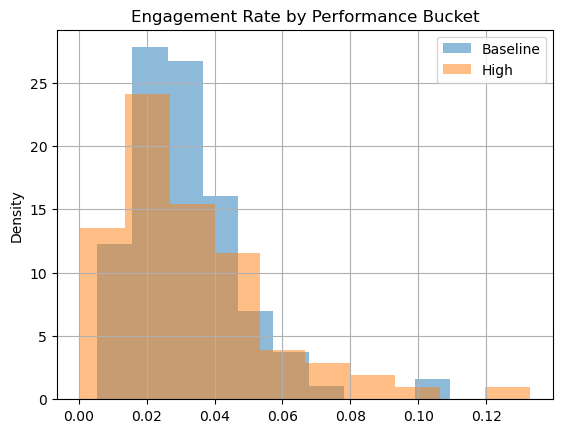

In [9]:
reels_df[reels_df['performance_bucket'] == 0]['engagement_rate'].hist(
    alpha=0.5, label='Baseline', density=True
)

reels_df[reels_df['performance_bucket'] == 1]['engagement_rate'].hist(
    alpha=0.5, label='High', density=True
)

plt.legend()
plt.title('Engagement Rate by Performance Bucket')
plt.ylabel('Density')
plt.show()

#### The distributions of engagement rate for baseline and high-performing reels overlap substantially, indicating that engagement alone does not clearly distinguish performance groups. However, high-performing reels exhibit a longer right tail, indicating a greater likelihood of achieving higher engagement values.

### Bar Charts

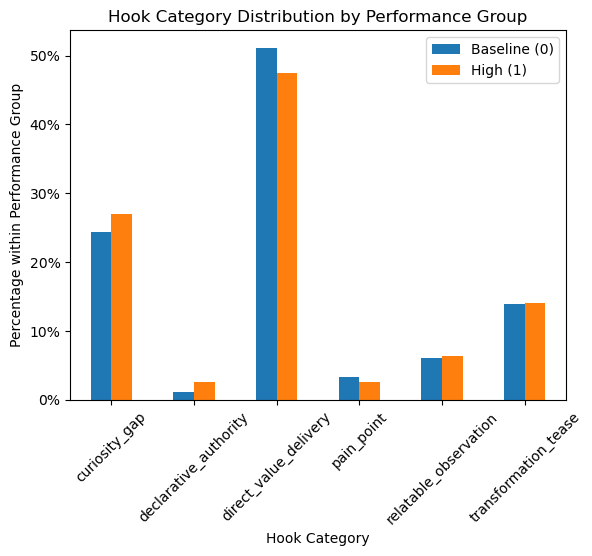

In [10]:
# Hook category vs performance
hook_labels = reels_df.filter(like='hook_category_').idxmax(axis=1)

ct = pd.crosstab(
    hook_labels,
    reels_df['performance_bucket'],
    normalize='columns'
)

ct.index = ct.index.str.replace('hook_category_', '', regex=False)

ct.plot(kind='bar')

plt.title('Hook Category Distribution by Performance Group')
plt.xlabel('Hook Category')
plt.ylabel('Percentage within Performance Group')
plt.legend(['Baseline (0)', 'High (1)'])

plt.gca().yaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
plt.xticks(rotation=45)
plt.show()

#### While most reels use direct_value_delivery regardless of performance, curiosity_gap is more represented among high-performing reels, suggesting a potential positive association, though overall differences across hook categories remain modest.

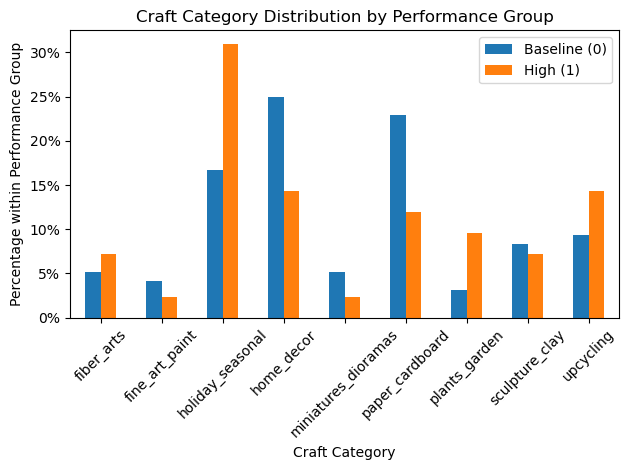

In [ ]:
# Craft category vs performance
craft_labels = reels_df.filter(like='craft_category_').idxmax(axis=1)

ct = pd.crosstab(
    craft_labels,
    reels_df['performance_bucket'],
    normalize='columns'
)

ct.index = ct.index.str.replace('craft_category_', '', regex=False)
ct.plot(kind='bar')

plt.title('Craft Category Distribution by Performance Group')
plt.xlabel('Craft Category')
plt.ylabel('Percentage within Performance Group')
plt.legend(['Baseline (0)', 'High (1)'])
plt.gca().yaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### This chart shows the distribution of craft categories within baseline and high-performing reels. Categories such as holiday_seasonal and upcycling are more represented among high-performing reels compared to baseline, while categories like home_decor and paper_cardboard are more represented among baseline reels. This suggests that certain craft categories may be more associated with stronger performance.

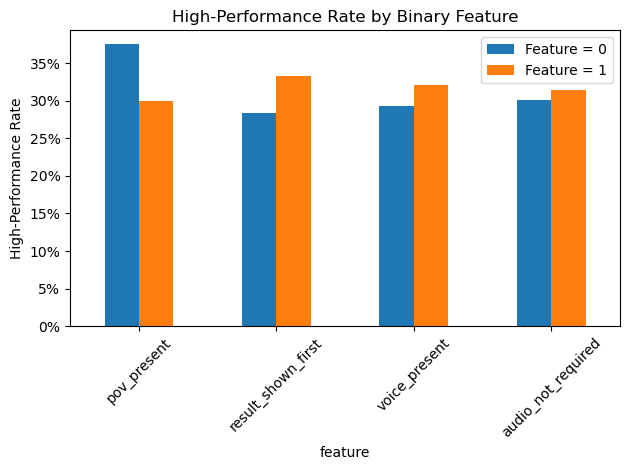

In [ ]:
# Binary Feature Analysis
binary_cols = [
    'pov_present',
    'result_shown_first',
    'voice_present',
    'audio_not_required'
]

results = []

for col in binary_cols:
    ct = pd.crosstab(
        reels_df[col],
        reels_df['performance_bucket'],
        normalize='index'
    )
    
    # Get high-performance rate (column = 1)
    rate_0 = ct.loc[0, 1] if (0 in ct.index and 1 in ct.columns) else None
    rate_1 = ct.loc[1, 1] if (1 in ct.index and 1 in ct.columns) else None
    
    results.append({
        'feature': col,
        'high_rate_0': rate_0,
        'high_rate_1': rate_1,
        'difference': (rate_1 - rate_0) if rate_0 is not None and rate_1 is not None else None
    })

summary_df = pd.DataFrame(results)

# Set feature as index for plotting
plot_df = summary_df.set_index('feature')[['high_rate_0', 'high_rate_1']]

plot_df.plot(kind='bar')

plt.title('High-Performance Rate by Binary Feature')
plt.ylabel('High-Performance Rate')
plt.xticks(rotation=45)
plt.legend(['Feature = 0', 'Feature = 1'])

# Format as percentages
plt.gca().yaxis.set_major_formatter(lambda x, _: f'{x:.0%}')

plt.tight_layout()
plt.show()

#### Reels that show the result first, include voice, or do not require audio are associated with a higher likelihood of high performance, as reflected in higher high-performance rates when these features are present. Among these, showing the result first appears to have the strongest positive association. In contrast, POV presence is associated with a lower high-performance rate when present, suggesting it may not be a strong differentiator of successful content.

### Boxplots

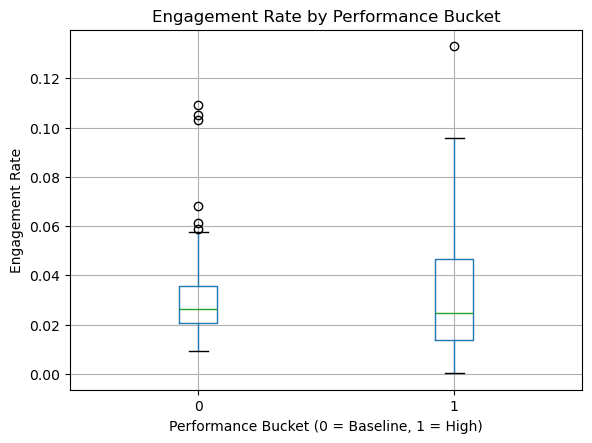

In [ ]:
# boxplots
reels_df.boxplot(
    column='engagement_rate',
    by='performance_bucket'
)

plt.title('Engagement Rate by Performance Bucket')
plt.suptitle('')  # removes automatic subtitle
plt.xlabel('Performance Bucket (0 = Baseline, 1 = High)')
plt.ylabel('Engagement Rate')

plt.show()

#### The boxplot shows similar median engagement rates between baseline and high-performing reels, but greater variability and higher extreme values among high-performing reels. This indicates that strong performance is associated with higher engagement outliers rather than consistently higher typical engagement.

---
---

# Correlation Analysis

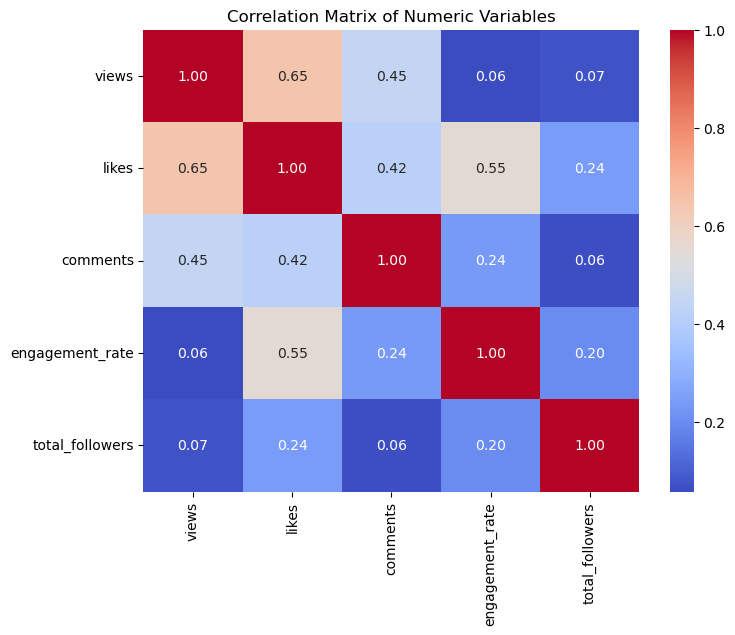

In [ ]:
numeric_cols = [
    'views',
    'likes',
    'comments',
    'engagement_rate',
    'total_followers'
]

corr_matrix = reels_df[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')

plt.title('Correlation Matrix of Numeric Variables')
plt.show()

#### A correlation matrix was used to examine relationships between numeric engagement variables. Strong positive correlations were observed between views, likes, and comments, indicating that these variables capture similar aspects of engagement volume. This high correlation suggests potential redundancy among these features.

#### Due to the strong correlations among views, likes, and comments, engagement rate was used as the primary performance-related metric, as it provides a normalized measure of engagement relative to views. This aligns with the problem objective of comparing performance across creators with different audience sizes. No additional variables were removed, as the primary analysis focuses on relationships between content features and the binary performance outcome.
---
---

# Principal Component Analysis (PCA)

#### Principal Component Analysis (PCA) was considered as a potential dimensionality reduction technique; however, it was not applied in this analysis. PCA is most appropriate for reducing dimensionality in datasets with a large number of continuous, highly correlated variables. In this dataset, the primary variables of interest are categorical features that have been converted into binary indicators, along with a limited number of numeric variables.

#### While some correlation exists among engagement metrics (e.g., views, likes, and comments), this was addressed by using engagement rate as a normalized measure of performance. Because the analysis focuses on interpreting relationships between specific content features and a binary performance outcome, applying PCA would reduce interpretability without providing meaningful benefit. Therefore, PCA was not used in this project.

---
---

# Data Cleaning

#### The dataset was cleaned and prepared to ensure consistency, accuracy, and suitability for analysis. Initial checks confirmed that there were no significant missing or duplicate values, so no records were removed on that basis.

#### Unnecessary columns, including hook_text and url, were dropped as they were not relevant to the analysis. The creator_handle variable was retained as an identifier to preserve the structure of the dataset, although it was not used directly in the analysis since it does not represent a measurable feature. Column names were standardized for clarity, and categorical values (e.g., craft categories and reel structures) were cleaned by converting to lowercase, removing extra spaces, and standardizing formatting to ensure consistency across categories.

#### Several variables originally stored as strings (e.g., views, likes, comments, and total_followers) were converted into numeric format to enable quantitative analysis. A new variable, engagement_rate, was created to measure engagement relative to views, providing a normalized metric for comparing performance across reels.

#### Categorical variables were transformed into binary (dummy) variables to support analysis of specific features such as hook type, craft category, and reel structure. Additionally, binary indicators (e.g., pov_present, result_shown_first) were encoded as 0/1 values for consistency.

#### No outliers were removed, as extreme values in engagement metrics are meaningful in the context of social media performance.

#### Finally, the target variable performance_bucket was converted into a binary format (0 = baseline, 1 = high-performing) to support comparative and predictive analysis.

---
---

# Predictive Modeling Approaches

#### Three classification models were selected to predict whether a Reel achieves above-baseline performance (performance_bucket): logistic regression, classification trees, and k-nearest neighbors (k-NN). These models were chosen based on their suitability for binary classification problems and their ability to handle the structure of the dataset.

#### Logistic regression was selected as a baseline model due to its interpretability and ability to estimate the probability of a Reel being high-performing. It allows for clear interpretation of how individual content features influence the likelihood of success.

#### A classification tree model was included to capture nonlinear relationships and interactions between features. This approach can model decision rules that reflect how combinations of content characteristics influence performance outcomes.

#### The k-nearest neighbors (k-NN) algorithm was selected as a non-parametric method that classifies observations based on similarity to other data points. This model does not assume a specific functional form and can provide a useful comparison to the more structured approaches of logistic regression and decision trees.

#### These approaches are appropriate because the target variable is binary and the dataset consists primarily of categorical features encoded as binary variables. Each model offers a different way of identifying patterns in the data, allowing for comparison of how content features relate to performance.

In [ ]:
# Export final cleaned data
reels_df.to_csv('../Data/cleaned_data.csv', index=False)